# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [9]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [10]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [11]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [12]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

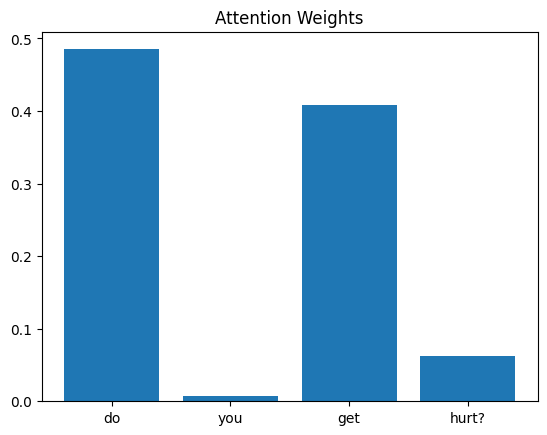

In [13]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

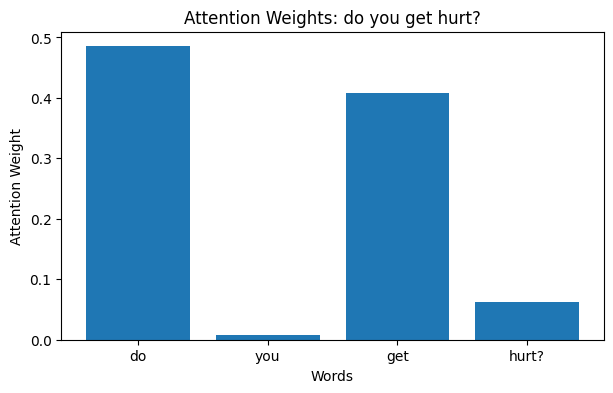

Question: do you get hurt?
Highest attention word: do
Attention weight: 0.48511698842048645
----------------------------------------


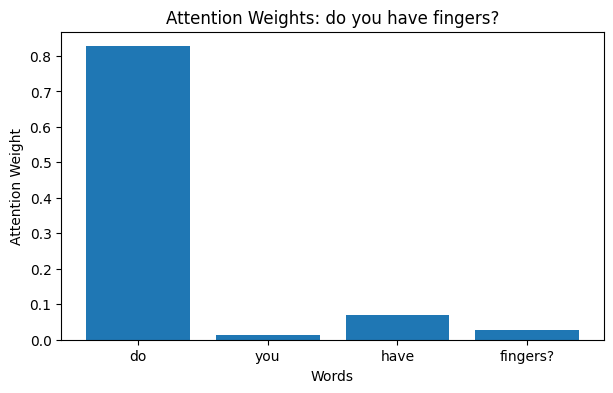

Question: do you have fingers?
Highest attention word: do
Attention weight: 0.826994776725769
----------------------------------------


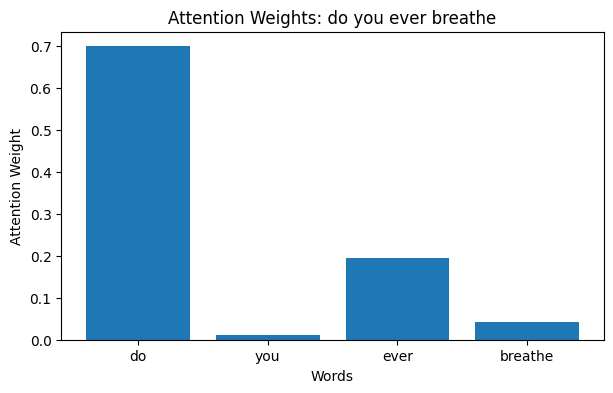

Question: do you ever breathe
Highest attention word: do
Attention weight: 0.6996210217475891
----------------------------------------


In [15]:

selected_questions = [0, 1, 2]

for i in selected_questions:

    question = df["question"].iloc[i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention_weights = weights[0, :len(words)].tolist()

    plt.figure(figsize=(7, 4))
    plt.bar(words, attention_weights)
    plt.title(f"Attention Weights: {question}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()

    highest_index = attention_weights.index(max(attention_weights))

    print("Question:", question)
    print("Highest attention word:", words[highest_index])
    print("Attention weight:", attention_weights[highest_index])
    print("-" * 40)

Yes some words have higher attention weights than others

This means the model focuses more on important words in the question these words help the model understand the question better

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question 1: what do you like to be called?
Question 2: so what do you like to be called?
Similarity: 0.942

First Question:


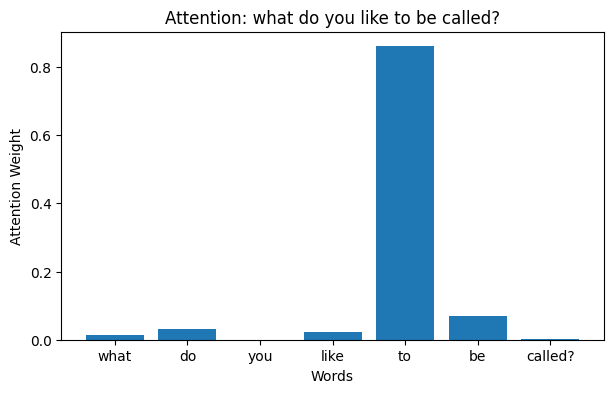

Highest attention word: to
Attention weight: 0.86

Second Question:


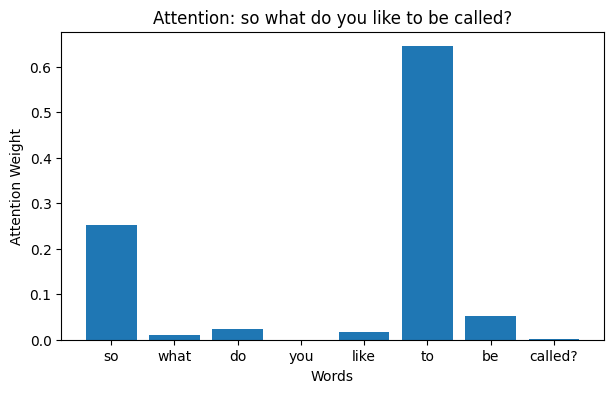

Highest attention word: to
Attention weight: 0.644


In [17]:

# Task 2: Compare attention for similar questions

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Find two different questions with the same answer_id
# and the highest text similarity

best_score = -1
best_pair = None

for answer_id in df["answer_id"].unique():
    group = df[df["answer_id"] == answer_id]

    questions = group["question"].tolist()
    indices = group.index.tolist()

    if len(questions) < 2:
        continue

    vectorizer = TfidfVectorizer()
    vectors = vectorizer.fit_transform(questions)
    similarity = cosine_similarity(vectors)

    for i in range(len(questions)):
        for j in range(i + 1, len(questions)):
            if questions[i] != questions[j]:
                score = similarity[i, j]

                if score > best_score:
                    best_score = score
                    best_pair = (indices[i], indices[j])

# Get the selected questions
idx1, idx2 = best_pair

q1 = df.loc[idx1, "question"]
q2 = df.loc[idx2, "question"]

print("Question 1:", q1)
print("Question 2:", q2)
print("Similarity:", round(best_score, 3))


# Visualize attention for each question
def show_attention(index, question):
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[index:index+1])

    attention_weights = weights[0, :len(words)].tolist()

    plt.figure(figsize=(7, 4))
    plt.bar(words, attention_weights)
    plt.title(f"Attention: {question}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()

    highest_index = attention_weights.index(max(attention_weights))

    print("Highest attention word:", words[highest_index])
    print("Attention weight:", round(attention_weights[highest_index], 3))


print("\nFirst Question:")
show_attention(idx1, q1)

print("\nSecond Question:")
show_attention(idx2, q2)


The model focuses on the word "to" in both questions.

This shows that attention gives high weights to some words. The model can focus on the same word in similar questions, even when the wording is slightly different.